# 10 – Pipeline per Konfigurationsdatei (Etappe 9, Stufe 2)

**Was:** Die ganze Kette mit `astropipe.run` aus einer TOML-Datei ausführen – für NGC 3132 und NGC 6720 (NIRCam) – und mit den Ergebnissen der Notebooks vergleichen.

**Warum:** Ein Skript ist nur dann ein Ersatz für die Notebooks, wenn es mit denselben Parametern dasselbe Bild liefert (Regressionstest, wie in Notebook 07). Erst danach bauen wir darauf den Entdecker-Modus auf.

**Im Terminal geht dasselbe mit:**
```bash
python -m astropipe.run configs/ngc3132.toml
```
Zwischenergebnisse landen in `data/<name>_run/`, Bilder in `output/runs/` (Web-JPEG + Bildunterschrift) und `output/full_res/`, alle verwendeten Werte in `params/<name>_run.json`.

## Ergebnis

`python -m astropipe.run configs/<name>.toml` reproduziert NGC 3132 und NGC 6720 aus den Konfigurationsdateien.
Im ersten Vergleich stimmten Streckung und Farbe bitgenau mit den Notebooks überein. Nach der Korrektur der Lückenfüllung (Etappe 9.3) unterscheiden sie sich **nur an defekten Pixeln**:

- Innerhalb der defekten Pixel (+2 px): max. |diff| = 1,0. Früher weiß gefüllt, jetzt Umgebungsmedian.
- Außerhalb: im Mittel 10⁻⁴–10⁻³, max. 1,5·10⁻² (NGC 3132 F090W), weil sich der Weißpunkt (99,9 %) leicht verschiebt.
- NGC 6720 F300M/F335M haben keine defekten Pixel und sind identisch.
- Ausschnitt NGC 3132: 1576 px statt 1578 px (Mitte 1570/1576).

**Ab jetzt sind die Skript-Ergebnisse (`output/runs/`, `params/*_run.json`) die Referenz.**

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import json
import numpy as np
from astropy.io import fits
from astropipe import run

ROOT = Path("..")

def report(name, a, b, tol=1e-5):
    d = np.nanmax(np.abs(np.asarray(a, np.float64) - np.asarray(b, np.float64)))
    print(f"{name:<30} max |diff| = {d:.2e}  {'OK' if d < tol else 'CHECK'}")

## 1. NGC 3132

Erwartung: Streckung und Farbbild C identisch zu den Notebooks 04/05 (Farbe dort mit exakten Farbwinkeln berechnet, hier ebenfalls).

In [2]:
info = run.run(ROOT / "configs" / "ngc3132.toml", root=ROOT)

[12:50:10] MAST: 6 i2d products, 6 selected (2.49 GB)
6 of 6 files already present, 0 to download (0.00 GB)
[12:50:10] target grid (3127, 3121)
F090W   exists -> ngc3132_f090w_reproj.fits
F187N   exists -> ngc3132_f187n_reproj.fits
F212N   exists -> ngc3132_f212n_reproj.fits
F356W   exists -> ngc3132_f356w_reproj.fits
F405N   exists -> ngc3132_f405n_reproj.fits
F470N   exists -> ngc3132_f470n_reproj.fits
[12:50:11] star offsets vs F470N: {'F090W': 0.36, 'F187N': 0.19, 'F212N': 0.32, 'F356W': 0.24, 'F405N': 0.42, 'F470N': 0.0}
[12:50:13] filled holes (saturated / bad px): F090W 157/239, F187N 41/216, F212N 23/186, F356W 351/158, F405N 0/245, F470N 0/162
[12:50:14] 6 sky boxes
[12:50:18] crop 1576 x 1576 px = 1.65' x 1.65'
[12:50:18] exported C_physical
[12:50:18] done in 9.5 s -> params/ngc3132_run.json


In [3]:
for b in ["F090W", "F187N", "F212N", "F356W", "F405N", "F470N"]:
    new = fits.getdata(ROOT / "data" / "ngc3132_run" / f"ngc3132_{b.lower()}_stretched.fits")
    old = fits.getdata(ROOT / "data" / "ngc3132_nircam_stretched" / f"ngc3132_{b.lower()}_stretched.fits")
    report(f"stretched {b}", new, old)
report("colour C_physical",
       np.load(ROOT / "data" / "ngc3132_run" / "ngc3132_C_physical.npy"),
       np.load(ROOT / "data" / "ngc3132_nircam_color" / "ngc3132_C_physical.npy"))
print("crop:", info["export"]["center_yx"], "half (h, w):", info["export"]["half_hw"], "(notebook 06: centre (1570, 1575), half 789)")

stretched F090W                max |diff| = 1.00e+00  CHECK
stretched F187N                max |diff| = 1.00e+00  CHECK
stretched F212N                max |diff| = 1.00e+00  CHECK
stretched F356W                max |diff| = 1.00e+00  CHECK
stretched F405N                max |diff| = 1.00e+00  CHECK
stretched F470N                max |diff| = 1.00e+00  CHECK
colour C_physical              max |diff| = 6.74e-01  CHECK
crop: [1570, 1576] half (h, w): [788, 788] (notebook 06: centre (1570, 1575), half 789)


## 2. NGC 6720

Mit lokaler Streifenkorrektur (`clean.method = "local"`). Erwartung: Streckung identisch zu Notebook 08 (Version `lw_dsl`), Ausschnitt wie dort: Mitte (1671, 1608), 1562 × 1172 px. Die Streifenkorrektur rechnet beim ersten Lauf einige Minuten.

In [4]:
info2 = run.run(ROOT / "configs" / "ngc6720.toml", root=ROOT)

[12:50:20] MAST: 4 i2d products, 4 selected (1.79 GB)
4 of 4 files already present, 0 to download (0.00 GB)
[12:50:20] target grid (3311, 3312)
F162M   exists -> ngc6720_f162m_reproj.fits
F212N   exists -> ngc6720_f212n_reproj.fits
F300M   exists -> ngc6720_f300m_reproj.fits
F335M   exists -> ngc6720_f335m_reproj.fits
[12:50:20] star offsets vs F335M: {'F162M': 0.16, 'F212N': 0.05, 'F300M': 0.02, 'F335M': 0.0}
[12:50:22] filled holes (saturated / bad px): F162M 97/49, F212N 0/51, F300M 95/0, F335M 85/0
[12:50:23] 4 sky boxes
[12:50:26] crop 1562 x 1172 px = 1.64' x 1.23'
[12:50:26] exported C_physical
[12:50:26] done in 6.9 s -> params/ngc6720_run.json


In [5]:
for b in ["F162M", "F212N", "F300M", "F335M"]:
    new = fits.getdata(ROOT / "data" / "ngc6720_run" / f"ngc6720_{b.lower()}_stretched.fits")
    old = fits.getdata(ROOT / "data" / "ngc6720_nircam_stretched" / f"ngc6720_{b.lower()}_stretched.fits")
    report(f"stretched {b}", new, old)
e = info2["export"]
print("crop centre:", e["center_yx"], "size px:", 2 * e["half_hw"][1], "x", 2 * e["half_hw"][0])
print("sky boxes used:", info2["stretch"]["sky_boxes"]["yx"])

stretched F162M                max |diff| = 1.00e+00  CHECK
stretched F212N                max |diff| = 1.00e+00  CHECK
stretched F300M                max |diff| = 0.00e+00  OK
stretched F335M                max |diff| = 0.00e+00  OK
crop centre: [1671, 1608] size px: 1562 x 1172
sky boxes used: [[1125, 2325], [2100, 2175], [450, 1575], [2400, 1125]]


NGC 3132 F090W: 15 holes – saturated 4 (157 px), bad 11 (239 px)


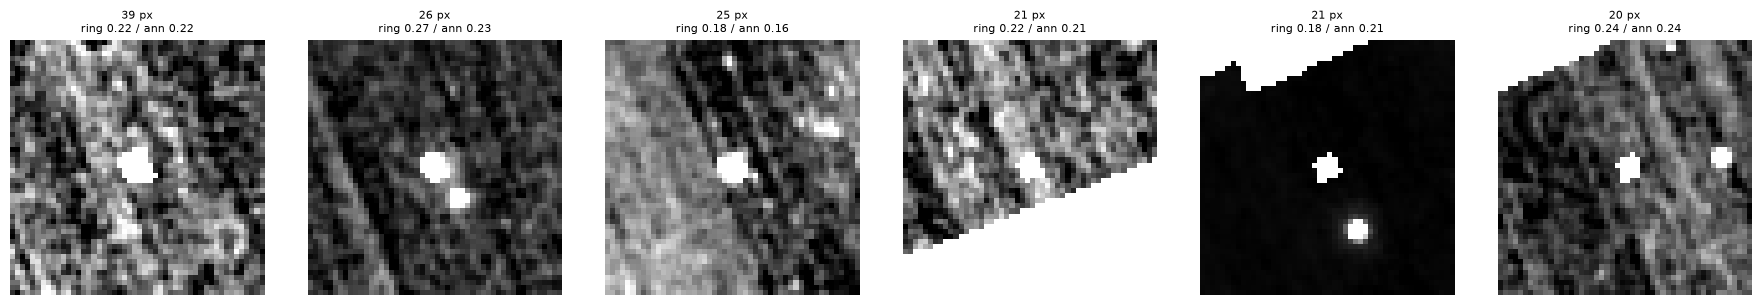

NGC 3132 F187N: 13 holes – saturated 2 (41 px), bad 11 (216 px)


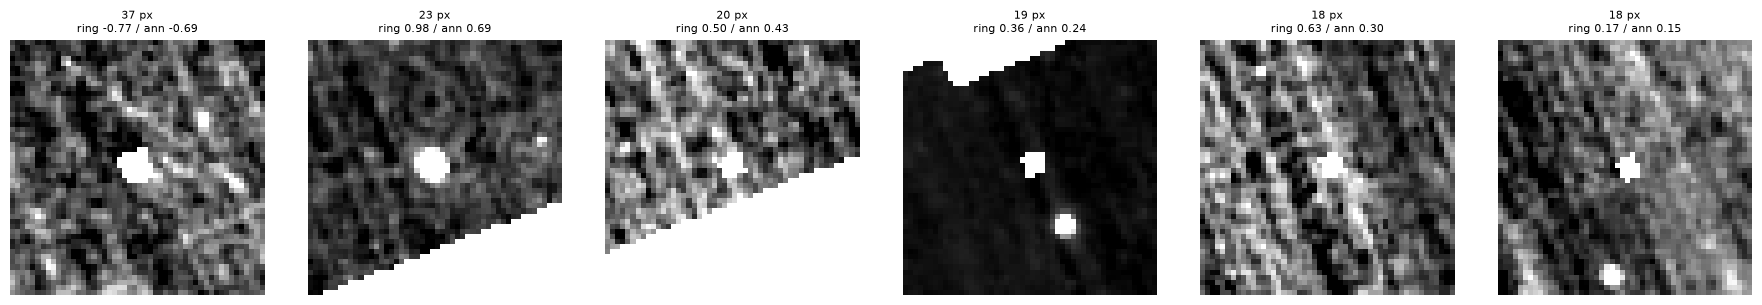

NGC 3132 F212N: 10 holes – saturated 1 (23 px), bad 9 (186 px)


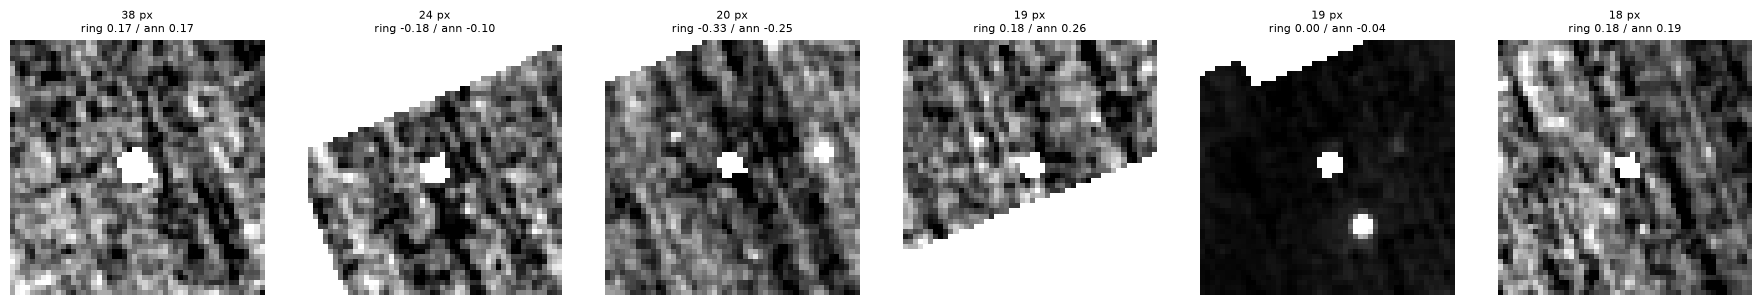

NGC 3132 F356W: 9 holes – saturated 3 (351 px), bad 6 (158 px)


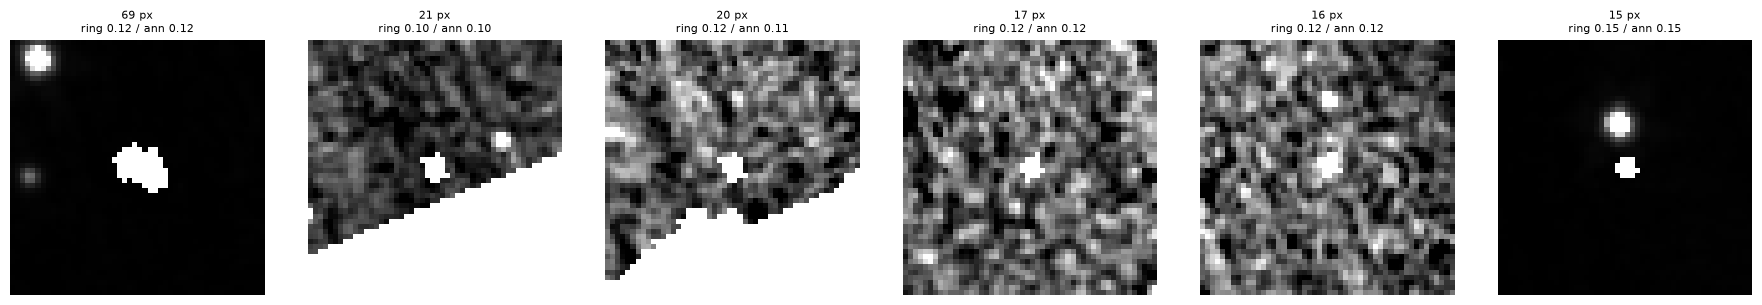

NGC 3132 F405N: 11 holes – saturated 0 (0 px), bad 11 (245 px)


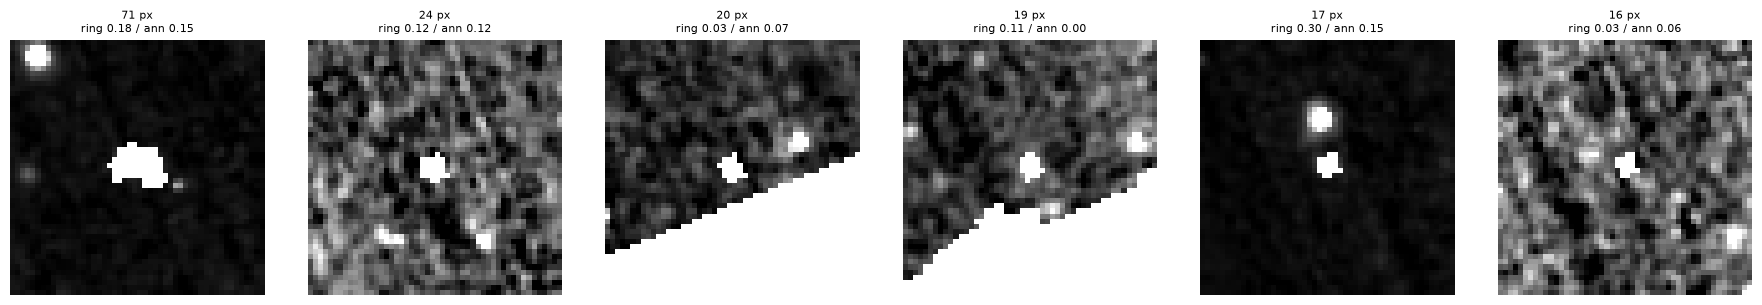

NGC 3132 F470N: 6 holes – saturated 0 (0 px), bad 6 (162 px)


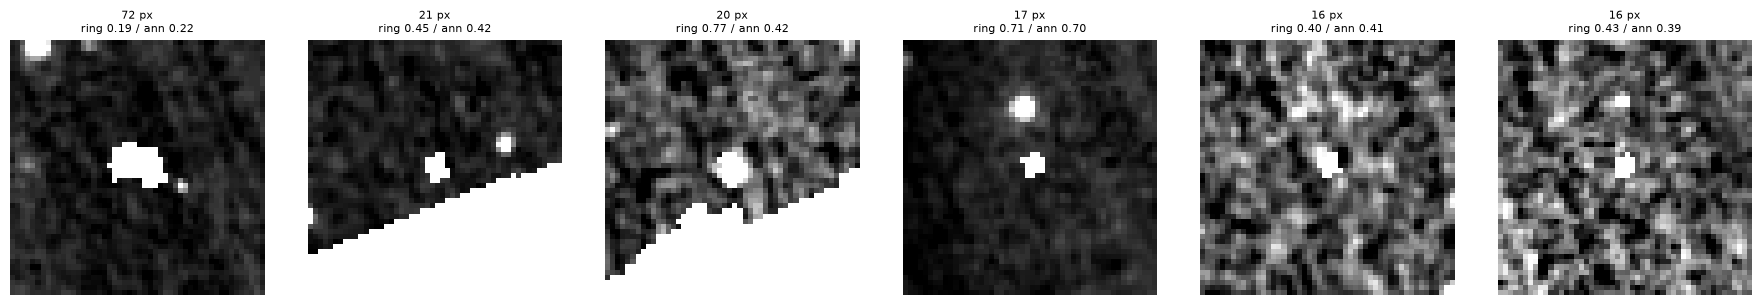

In [6]:
import matplotlib.pyplot as plt
from astropipe import stretch

def hole_report(path, title, show_bad=6):
    img = fits.getdata(path).astype(np.float32)
    lab, holes = stretch.classify_holes(img)
    sat = [h for h in holes if h["saturated"]]
    bad = sorted([h for h in holes if not h["saturated"]], key=lambda h: -h["size"])
    print(f"{title}: {len(holes)} holes – saturated {len(sat)} ({sum(h['size'] for h in sat)} px), "
          f"bad {len(bad)} ({sum(h['size'] for h in bad)} px)")
    if bad:
        n = min(show_bad, len(bad))
        fig, axes = plt.subplots(1, n, figsize=(3 * n, 3), squeeze=False)
        for ax, h in zip(axes[0], bad[:n]):
            y, x = h["yx"]
            cut = img[max(y - 25, 0):y + 25, max(x - 25, 0):x + 25]
            ax.imshow(np.nan_to_num(cut, nan=np.nanmax(cut)), origin="lower", cmap="gray",
                      vmin=np.nanpercentile(cut, 5), vmax=np.nanpercentile(cut, 99.5))
            ax.set_title(f"{h['size']} px\nring {h['ring']:.2f} / ann {h['annulus']:.2f}", fontsize=8)
            ax.axis("off")
        plt.tight_layout(); plt.show()

for b in ["F090W", "F187N", "F212N", "F356W", "F405N", "F470N"]:
    hole_report(ROOT / "data" / "ngc3132_run" / "reproj" / f"ngc3132_{b.lower()}_reproj.fits", f"NGC 3132 {b}")

In [7]:
from scipy.ndimage import binary_dilation

def check_outside_bad(name, bands, old_dir, old_fmt, run_name):
    for b in bands:
        raw = fits.getdata(ROOT / "data" / f"{run_name}_run" / "reproj" / f"{run_name}_{b.lower()}_reproj.fits").astype(np.float32)
        lab, holes = stretch.classify_holes(raw)
        bad = np.isin(lab, [h["label"] for h in holes if not h["saturated"]])
        bad = binary_dilation(bad, iterations=2)
        new = fits.getdata(ROOT / "data" / f"{run_name}_run" / f"{run_name}_{b.lower()}_stretched.fits")
        old = fits.getdata(ROOT / "data" / old_dir / old_fmt.format(b=b.lower()))
        d = np.abs(new.astype(np.float64) - old)
        print(f"{name} {b:<6} inside bad holes: max {d[bad].max() if bad.any() else 0:.3f}  |  "
              f"outside: max {d[~bad].max():.2e}, mean {d[~bad].mean():.2e}  ({bad.sum()} px masked)")

check_outside_bad("NGC 3132", ["F090W", "F187N", "F212N", "F356W", "F405N", "F470N"],
                  "ngc3132_nircam_stretched", "ngc3132_{b}_stretched.fits", "ngc3132")
check_outside_bad("NGC 6720", ["F162M", "F212N", "F300M", "F335M"],
                  "ngc6720_nircam_stretched", "ngc6720_{b}_stretched.fits", "ngc6720")

NGC 3132 F090W  inside bad holes: max 1.000  |  outside: max 1.50e-02, mean 1.36e-03  (665 px masked)
NGC 3132 F187N  inside bad holes: max 1.000  |  outside: max 1.17e-03, mean 1.25e-04  (626 px masked)
NGC 3132 F212N  inside bad holes: max 1.000  |  outside: max 1.86e-03, mean 3.11e-04  (530 px masked)
NGC 3132 F356W  inside bad holes: max 1.000  |  outside: max 7.14e-03, mean 9.60e-04  (408 px masked)
NGC 3132 F405N  inside bad holes: max 1.000  |  outside: max 1.23e-03, mean 1.29e-04  (672 px masked)
NGC 3132 F470N  inside bad holes: max 1.000  |  outside: max 1.55e-03, mean 2.43e-04  (417 px masked)
NGC 6720 F162M  inside bad holes: max 1.000  |  outside: max 3.82e-03, mean 4.95e-04  (101 px masked)
NGC 6720 F212N  inside bad holes: max 1.000  |  outside: max 5.46e-04, mean 7.47e-05  (103 px masked)
NGC 6720 F300M  inside bad holes: max 0.000  |  outside: max 0.00e+00, mean 0.00e+00  (0 px masked)
NGC 6720 F335M  inside bad holes: max 0.000  |  outside: max 0.00e+00, mean 0.00e+00

## Fazit

- `python -m astropipe.run configs/<name>.toml` führt die ganze Kette aus (Download, optionale Streifenkorrektur, Registrierung, Hintergrund, Streckung, Farbe, Ausschnitt, Export mit Bildunterschrift) und protokolliert alle Werte in `params/<name>_run.json`. Die Notebooks bleiben als Erklärung und zum Ausprobieren.
- **Regressionstest, 1. Durchlauf bestanden:** NGC 3132 und NGC 6720 lieferten **bitgenau** dieselben gestreckten Bilder wie die Notebooks, NGC 3132 auch dasselbe Farbbild (Farbwinkel statt gerundeter RGB-Werte → exakt). Ausschnitte und Himmelsboxen identisch.
- **2. Durchlauf nach der Lückenkorrektur (Etappe 9.3):** Unterschiede nur an defekten Pixeln (max. |diff| 1,0), sonst im Mittel 10⁻⁴–10⁻³, höchstens 1,5·10⁻² (Weißpunkt verschoben); F300M/F335M weiterhin identisch. Der Test hat damit einen echten Fehler aufgedeckt, der seit Etappe 4 bestand: Lücken aus defekten Pixeln wurden wie gesättigte Sternkerne weiß gefüllt. **Ab jetzt sind die Skript-Ergebnisse die Referenz.**
- Lehre: Ein CHECK heißt nicht automatisch, dass das neue Ergebnis falsch ist. Erst Diagnose (Ausschnitte, Masken innen/außen), dann entscheiden, welche Version die richtige ist.
- Analogie Mikroskopie: Hot Pixel und überbelichtete Zellen sehen beide „hell“ aus. Was sie unterscheidet, ist die Umgebung.
- **Laufzeit:** wenige Sekunden mit vorhandenen Zwischenergebnissen, ≈ 1,5 min für NGC 6720 von den Rohdaten an; auch im Terminal getestet.
- **Offen:** Stufe 2b (NIRCam + MIRI im Skript: Instrumentenversatz, LRGB, Schärfe angleichen); `09a` mit der neuen Lückenfüllung neu laufen lassen.